# Markowitz mean-variance optimization: baseline

Baseline for the individual ECE556 portfolio allocation project. Saved outputs include validation Sharpe 2.6466 and test Sharpe 0.3283. Install the root `requirements.txt` only if you intend to execute this notebook. No execution was performed during publication.

See [experiment notes](../docs/experiment_notes.md) for differences between the supplied baseline implementation and the final report.


In [ ]:
# === INSTALL DEPENDENCIES ===

# === IMPORTS ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.preprocessing import StandardScaler
from scipy.optimize import minimize

# === STEP 1: DOWNLOAD AND PREPARE RETURNS ===
tickers = ['AAPL', 'MSFT', 'TSLA', 'AMZN', 'GOOG']
data = yf.download(tickers, start='2015-01-01', end='2025-06-30', auto_adjust=True)['Close'].dropna()

returns = np.log(data / data.shift(1)).dropna()
returns.columns = [f"Asset_{i+1}" for i in range(len(returns.columns))]
log_returns = returns.copy()  # For evaluation and plotting

scaler = StandardScaler()
scaled_returns = pd.DataFrame(scaler.fit_transform(returns), index=returns.index, columns=returns.columns)

# === STEP 2: SPLIT DATASETS ===
train_scaled = scaled_returns.loc["2015-01-01":"2020-12-31"].copy()
val_scaled = scaled_returns.loc["2021-01-01":"2023-12-31"].copy()
test_scaled = scaled_returns.loc["2024-01-01":"2024-12-31"].copy()

train_returns = log_returns.loc["2015-01-01":"2020-12-31"].copy()
val_returns = log_returns.loc["2021-01-01":"2023-12-31"].copy()
test_returns = log_returns.loc["2024-01-01":"2024-12-31"].copy()

Validation Sharpe Ratio (MVO): 2.6466


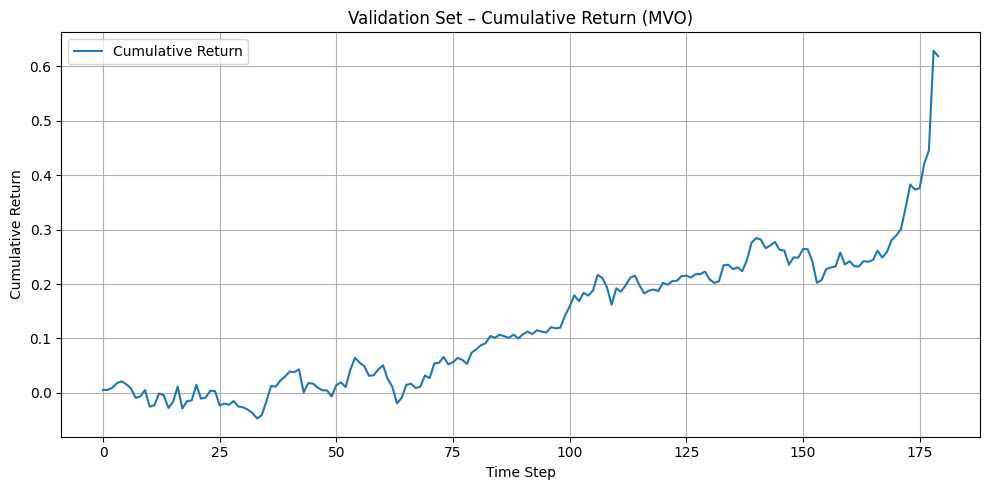

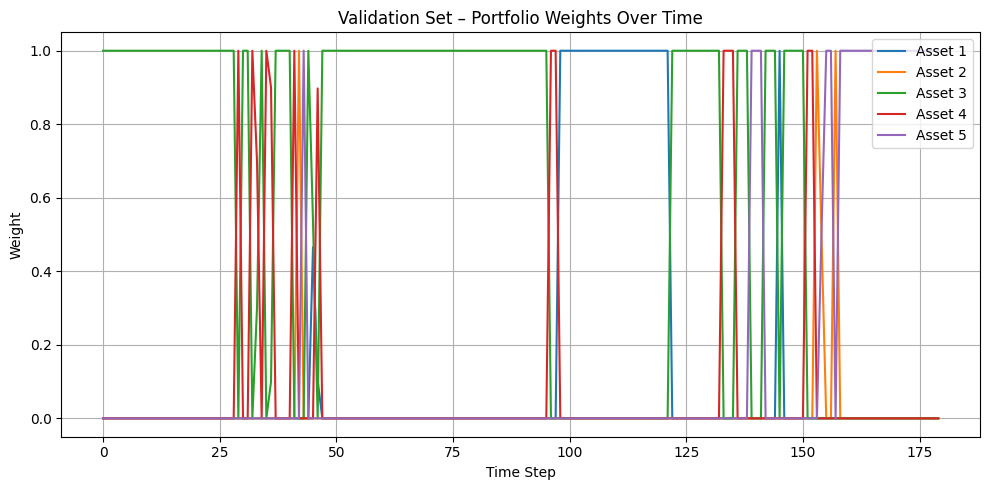

Test Sharpe Ratio (MVO): 0.3283


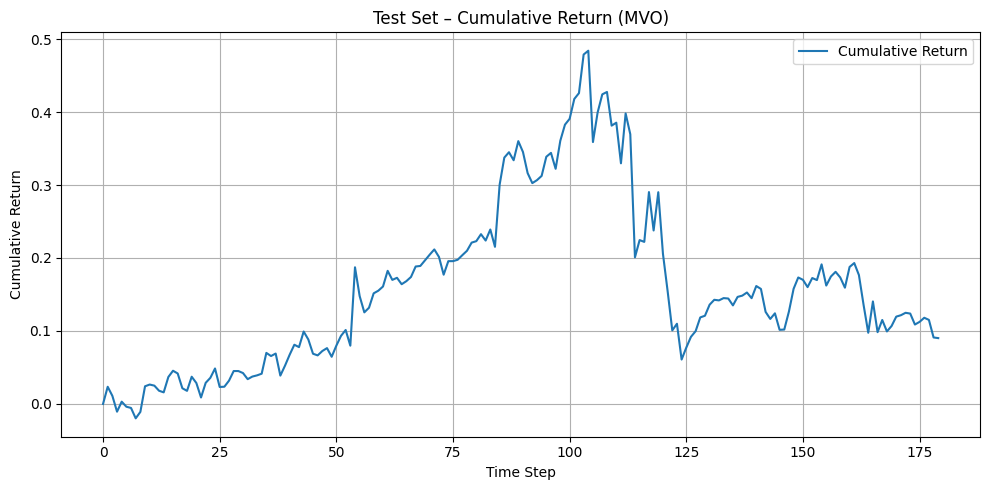

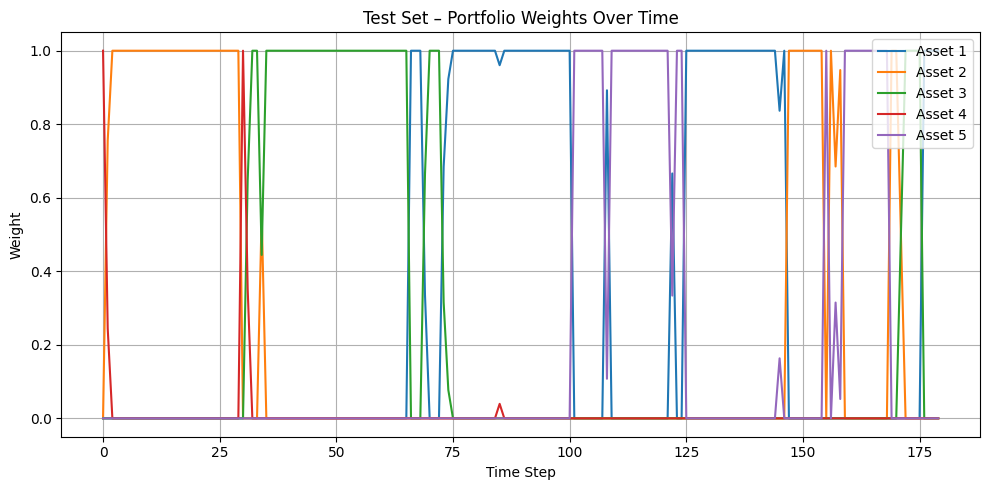

In [ ]:
# === CONFIGURATION ===
window_size = 25
episode_length = 180
risk_aversion = 0.01
transaction_cost_rate = 0.0001
penalty_weight = 0.0005

# === MVO OPTIMIZER ===
def mean_variance_optimization(mu, cov, risk_aversion):
    n_assets = len(mu)

    def objective(w):
        return -w @ mu + risk_aversion * w @ cov @ w

    constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}]
    bounds = [(0.0, 1.0) for _ in range(n_assets)]

    w0 = np.ones(n_assets) / n_assets
    result = minimize(objective, w0, bounds=bounds, constraints=constraints)
    return result.x if result.success else w0

# === SIMULATE MVO PORTFOLIO ===
def run_mvo_episode(returns_df, scaled_df, start_idx, window_size=25, episode_length=180):
    portfolio_returns = []
    weights_list = []

    prev_weights = np.ones(returns_df.shape[1]) / returns_df.shape[1]

    for t in range(start_idx, start_idx + episode_length):
        window = scaled_df.iloc[t - window_size + 1: t + 1].values
        mu = np.mean(window, axis=0)
        cov = np.cov(window.T)

        weights = mean_variance_optimization(mu, cov, risk_aversion)
        r_t = returns_df.iloc[t + 1].values
        raw_ret = np.dot(weights, r_t)

        turnover = np.sum(np.abs(weights - prev_weights))
        transaction_cost = transaction_cost_rate * turnover
        allocation_penalty = penalty_weight * np.sum((weights - prev_weights) ** 2)

        adjusted_ret = raw_ret - transaction_cost - allocation_penalty

        portfolio_returns.append(adjusted_ret)
        weights_list.append(weights)
        prev_weights = weights

    return np.array(portfolio_returns), np.array(weights_list)

# === SHARPE RATIO ===
def sharpe_ratio(returns):
    return np.mean(returns) / (np.std(returns) + 1e-8) * np.sqrt(252)

# === PLOT FUNCTIONS ===
def plot_simple_cumulative_returns(log_returns, title):
    simple_returns = np.exp(log_returns) - 1
    cumulative_simple = np.cumprod(1 + simple_returns) - 1

    plt.figure(figsize=(10, 5))
    plt.plot(cumulative_simple, label='Cumulative Return')
    plt.title(title)
    plt.xlabel("Time Step")
    plt.ylabel("Cumulative Return")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

def plot_weights(weights_array, title):
    plt.figure(figsize=(10, 5))
    for i in range(weights_array.shape[1]):
        plt.plot(weights_array[:, i], label=f"Asset {i+1}")
    plt.title(title)
    plt.xlabel("Time Step")
    plt.ylabel("Weight")
    plt.legend(loc='upper right')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# === VALIDATION RUN ===
val_start = window_size
val_returns_arr, val_weights_arr = run_mvo_episode(val_returns, val_scaled, val_start)
print(f"Validation Sharpe Ratio (MVO): {sharpe_ratio(val_returns_arr):.4f}")
plot_simple_cumulative_returns(val_returns_arr, "Validation Set – Cumulative Return (MVO)")
plot_weights(val_weights_arr, "Validation Set – Portfolio Weights Over Time")

# === TEST RUN ===
test_start = window_size
test_returns_arr, test_weights_arr = run_mvo_episode(test_returns, test_scaled, test_start)
print(f"Test Sharpe Ratio (MVO): {sharpe_ratio(test_returns_arr):.4f}")
plot_simple_cumulative_returns(test_returns_arr, "Test Set – Cumulative Return (MVO)")
plot_weights(test_weights_arr, "Test Set – Portfolio Weights Over Time")